In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score
import tensorflow as tf
from tensorflow.keras import models, layers, utils
import random

-- LECTURE ET NETTOYAGE DES DONNÉES --

In [2]:
x_train = pd.read_csv('X_train_78VdSWL.csv')
x_train.head()

,Horodate,5423908671,2568793410,8310762594,6235194807,423895617,193845276,216589743,218753964,1794650328,...,holed_991,holed_992,holed_993,holed_994,holed_995,holed_996,holed_997,holed_998,holed_999,holed_1000
0,2023-01-09 00:00:00,352.0,0.0,371.0,110.0,724.0,102.0,256.0,7.0,105.0,...,0.0,32.0,152.0,NaN,0.0,1099.0,117.0,45.0,253.0,186.0
1,2023-01-09 00:30:00,405.0,0.0,363.0,108.0,478.0,147.0,281.0,8.0,134.0,...,0.0,34.0,84.0,NaN,NaN,782.0,109.0,40.0,227.0,180.0
2,2023-01-09 01:00:00,599.0,0.0,352.0,93.0,832.0,155.0,295.0,5.0,96.0,...,0.0,30.0,24.0,NaN,0.0,630.0,375.0,58.0,237.0,166.0
3,2023-01-09 01:30:00,315.0,0.0,348.0,84.0,574.0,152.0,267.0,15.0,156.0,...,0.0,34.0,24.0,NaN,0.0,773.0,468.0,48.0,245.0,525.0
4,2023-01-09 02:00:00,448.0,0.0,364.0,73.0,421.0,176.0,346.0,38.0,97.0,...,0.0,30.0,46.0,NaN,0.0,879.0,534.0,41.0,175.0,372.0


In [3]:
y_train = pd.read_csv('y_train_u0UkKEh.csv')
y_train.head()

,Horodate,holed_1,holed_2,holed_3,holed_4,holed_5,holed_6,holed_7,holed_8,holed_9,...,holed_991,holed_992,holed_993,holed_994,holed_995,holed_996,holed_997,holed_998,holed_999,holed_1000
0,2023-01-09 00:00:00,578.0,698.0,17.0,2.0,283.0,154.0,131.0,619.0,107.0,...,0.0,32.0,152.0,121.0,0.0,1099.0,117.0,45.0,253.0,186.0
1,2023-01-09 00:30:00,533.0,224.0,18.0,2.0,1047.0,150.0,106.0,542.0,114.0,...,0.0,34.0,84.0,107.0,0.0,782.0,109.0,40.0,227.0,180.0
2,2023-01-09 01:00:00,623.0,246.0,17.0,5.0,1185.0,131.0,74.0,517.0,109.0,...,0.0,30.0,24.0,128.0,0.0,630.0,375.0,58.0,237.0,166.0
3,2023-01-09 01:30:00,613.0,643.0,17.0,18.0,746.0,77.0,146.0,455.0,113.0,...,0.0,34.0,24.0,200.0,0.0,773.0,468.0,48.0,245.0,525.0
4,2023-01-09 02:00:00,1823.0,318.0,18.0,15.0,560.0,125.0,82.0,551.0,104.0,...,0.0,30.0,46.0,792.0,0.0,879.0,534.0,41.0,175.0,372.0


In [4]:
x_test = pd.read_csv('X_test_XKVc4no.csv')
x_test.head()

,Horodate,123476859,123596487,123798654,123875946,123879645,123897645,123947865,124367958,124568973,...,holed_991,holed_992,holed_993,holed_994,holed_995,holed_996,holed_997,holed_998,holed_999,holed_1000
0,2023-01-09 00:00:00,102.0,992.0,365.0,252.0,71.0,132.0,30.0,201.0,121.0,...,38.0,168.0,32.0,NaN,445.0,NaN,NaN,767.0,2029.0,129.0
1,2023-01-09 00:30:00,89.0,996.0,351.0,219.0,47.0,140.0,31.0,173.0,186.0,...,27.0,82.0,48.0,NaN,492.0,207.0,NaN,773.0,1698.0,113.0
2,2023-01-09 01:00:00,134.0,841.0,314.0,213.0,55.0,114.0,38.0,204.0,251.0,...,37.0,102.0,44.0,NaN,461.0,218.0,NaN,613.0,1737.0,NaN
3,2023-01-09 01:30:00,130.0,961.0,228.0,253.0,35.0,103.0,35.0,176.0,305.0,...,13.0,78.0,33.0,NaN,491.0,104.0,NaN,691.0,994.0,135.0
4,2023-01-09 02:00:00,135.0,949.0,213.0,243.0,47.0,472.0,21.0,187.0,283.0,...,62.0,107.0,36.0,NaN,451.0,97.0,NaN,844.0,1044.0,NaN


In [5]:
x_train_clean = x_train.drop('Horodate', axis=1)

x_train_clean = x_train_clean.interpolate(method='linear', limit_direction='both').fillna(0)
x_complete = x_train_clean.iloc[:, :20000] #on utilise les 20000 premieres données

y_train_clean = y_train.drop('Horodate', axis=1)
y_train_clean = y_train_clean.interpolate(method='linear', limit_direction='both').fillna(0)
holed_names = y_train_clean.columns   # on récupère le nom des colonnes qui ont des données manquantes (holed_...)

x_test_holed = x_train[holed_names] # Les courbes avec trous
masques = x_test_holed.isna().values # Les masques
nb_masques = masques.shape[1]

idée : réseau de neurone avec deux régressions : une par rapport à la courbe et une autre par rapport aux autres courbes (horodate)

L'idée : Pour chaque courbe à trous (ex: holed_1), 
on cherche les 10 ou 20 courbes complètes qui lui ressemblent le plus (plus forte corrélation linéaire), 
et on fait une régression multiple uniquement sur celles-là.

CRÉATION DES CLUSTERING

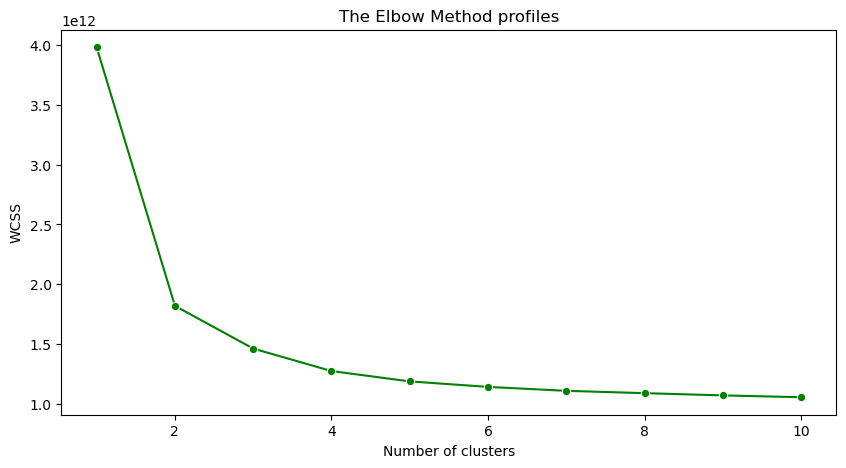

In [6]:
random.seed(10)
wcss = []
x_complete.columns = x_complete.columns.astype(str)
for i in range(1,11):
    kmeans=KMeans(n_clusters=i, random_state=0)
    kmeans.fit(x_complete.T)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10,5))
sns.lineplot(x=range(1,11), y=wcss, marker='o', color='green')
plt.title('The Elbow Method profiles')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

In [7]:
# clustering sur les profils client avec 4 clusters

model_profil=KMeans(n_clusters=4, random_state=0)
model_profil.fit(x_complete.T)
profil_label = model_profil.labels_
profil_label

array([0, 2, 3, ..., 0, 2, 3], shape=(20000,), dtype=int32)

on fait pareil pour les heures

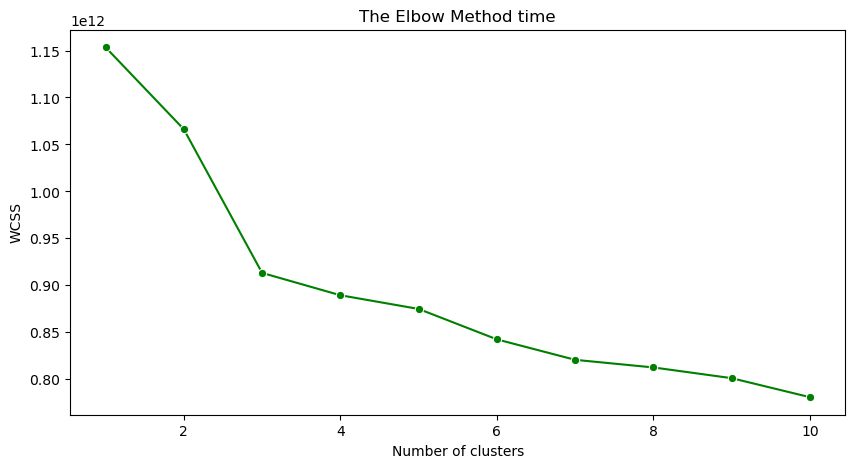

In [8]:
wcss = []
x_complete.columns = x_complete.columns.astype(str)
for i in range(1,11):
    kmeans=KMeans(n_clusters=i, random_state=0)
    kmeans.fit(x_complete)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10,5))
sns.lineplot(x=range(1,11), y=wcss, marker='o', color='green')
plt.title('The Elbow Method time')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

In [9]:
#clustering selon les heures 

random.seed(10)
model_heure=KMeans(n_clusters=3, random_state=0)
model_heure.fit(x_complete)
heure_labels = model_heure.labels_
heure_binaire = utils.to_categorical(heure_labels, 3)
heure_labels

array([2, 2, 2, ..., 0, 0, 0], shape=(1057,), dtype=int32)

-- CRÉATION DU RÉSEAU DE NEURONES --

In [10]:
model = models.Sequential()
model.add(layers.Dense(128, activation='relu', input_dim=1 + 4 + 3))  # 8 entrées 
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(1, activation='linear'))
model.compile(optimizer='adam', loss='mean_absolute_error')

/opt/miniconda3/lib/python3.13/site-packages/keras/src/layers/core/dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


-- ENTRAINEMENT --

In [11]:
x_train_source = x_complete.iloc[:, :20000].values

nb_donnees_entrainement = 10000  

random_indices = np.random.choice(20000, nb_donnees_entrainement, replace=False)
x_train_new = x_train_source[:, random_indices]

selection_masques = masques[:, np.random.randint(0, nb_masques, nb_donnees_entrainement)]

x_entree = []
y_pred = []
liste_masques = [] 

for i in range(nb_donnees_entrainement):
    courbe_saine = x_train_new[:, i]
    masque = selection_masques[:, i]
    
    if masque.sum() == 0: continue

    courbe_trou = courbe_saine.copy()
    courbe_trou[masque] = np.nan
    
    interp = pd.Series(courbe_trou).interpolate(method='linear').fillna(0).values
    profil_type = utils.to_categorical(model_profil.predict(interp.reshape(1, -1))[0], num_classes=4)
    profil_type_heure = np.tile(profil_type, (len(courbe_saine), 1))
    
    entree_model = np.hstack([interp.reshape(-1, 1), profil_type_heure, heure_binaire])
    
    target_residu = (courbe_saine - interp).reshape(-1, 1)
    
    x_entree.append(entree_model)
    y_pred.append(target_residu)
    liste_masques.append(masque.reshape(-1, 1))
    
if x_entree:
    x_train_final = np.vstack(x_entree)
    y_train_final = np.vstack(y_pred)
    masques_train_final = np.vstack(liste_masques).flatten().astype(bool)
    
    model.fit(x_train_final, y_train_final, epochs=3, batch_size=128, verbose=1)
    

Epoch 1/3
82579/82579 ━━━━━━━━━━━━━━━━━━━━ 90s 1ms/step - loss: 12.7701 
Epoch 2/3
82579/82579 ━━━━━━━━━━━━━━━━━━━━ 89s 1ms/step - loss: 12.7535 
Epoch 3/3
82579/82579 ━━━━━━━━━━━━━━━━━━━━ 88s 1ms/step - loss: 12.7531 


-- CALCUL DES SCORES --

In [12]:
pred_correction = model.predict(x_train_final, verbose=0).flatten()

valeur_interpolee = x_train_final[:, 0] #on récupère l'interpolation de chaque point
    
valeur_reelle_reconstruite = valeur_interpolee + y_train_final.flatten()
valeur_predite_reconstruite = valeur_interpolee + pred_correction  
    
y_true_holes = valeur_reelle_reconstruite[masques_train_final]
y_pred_holes = valeur_predite_reconstruite[masques_train_final]
    
mae_train = mean_absolute_error(y_true_holes, y_pred_holes)
r2_train = r2_score(y_true_holes, y_pred_holes)
    
print("mae train : ", mae_train)
print("r2 train : ", r2_train)

mae train :  103.51475833140312
r2 train :  0.7439806308522251


In [13]:
data_source = x_train_clean.iloc[:, -1000:] 
valeurs_source = data_source.values
nb_courbes = valeurs_source.shape[1]

nb_courbes_test = x_holed.shape[1]
x_test_entree = []
liste_trous = [] 

for i in range(nb_courbes_test):
    courbe = x_holed[:, i]
    trous = pd.isna(courbe)
    interp = pd.Series(courbe).interpolate(method='linear').fillna(0).values

    profil_type = utils.to_categorical(model_profil.predict(interp.reshape(1, -1))[0], num_classes=4)
    profil_type_heure = np.tile(profil_type, (len(x_holed), 1)) 
    
    entree_model = np.hstack([interp.reshape(-1, 1), profil_type_heure, heure_binaire])
    
    x_test_entree.append(entree_model)
    liste_trous.append(trous.reshape(-1, 1)) 

if x_test_entree:
    x_test_final = np.vstack(x_test_entree)
    trous_test_final = np.vstack(liste_trous).flatten().astype(bool)
    

pred_correction_test = model.predict(x_test_final, verbose=0).flatten()

valeur_interpolee = x_test_final[:, 0] #on récupère l'interpolation de chaque point
    
valeur_reelle = y_train_clean.iloc[:, -1000:].values.flatten(order='F')
valeur_predite_reconstruite = valeur_interpolee + pred_correction_test  


y_true_holes = valeur_reelle[trous_test_final]
y_pred_holes = valeur_predite_reconstruite[trous_test_final]
    
mae_test = mean_absolute_error(y_true_holes, y_pred_holes)
r2_test = r2_score(y_true_holes, y_pred_holes)
    
print("mae test : ", mae_test)
print("r2 test : ", r2_test)

mae test :  103.10273356292964
r2 test :  0.767841948080205


In [14]:
x_test_1000_df = x_test.iloc[:, -1000:]
noms_colonnes = x_test_1000_df.columns

x_test_1000 = x_test_1000_df.values 
data_source = x_test_1000

valeurs_source = data_source 
nb_courbes = valeurs_source.shape[1]
nb_courbes_test = x_test_1000.shape[1]
x_test_entree = []

for i in range(nb_courbes_test):
    courbe = x_test_1000[:, i]
    
    interp = pd.Series(courbe).interpolate(method='linear').fillna(0).values
    profil_type = utils.to_categorical(model_profil.predict(interp.reshape(1, -1))[0], num_classes=4)
    profil_type_heure = np.tile(profil_type, (len(x_test_1000), 1)) 
    
    entree_model = np.hstack([interp.reshape(-1, 1), profil_type_heure, heure_binaire])
    
    x_test_entree.append(entree_model)

if x_test_entree:
    x_test_final = np.vstack(x_test_entree)
    

pred_correction = model.predict(x_test_final, verbose=0)

valeur_interpolee_test = x_test_final[:, 0]

valeur_predite_reconstruite = valeur_interpolee_test + pred_correction.flatten()

matrice_reconstruite = valeur_predite_reconstruite.reshape(1000, -1).T
df_reconstruit = pd.DataFrame(matrice_reconstruite, columns=noms_colonnes)
df_reconstruit.insert(0, "Horodate", y_train["Horodate"].values)
df_reconstruit.to_csv("y_test.csv", index=False) 

print(df_reconstruit.shape)

(1057, 1001)
